# Data Preparation

Càrrega, validació i divisió del dataset. 
| | |
|---|---|
| **Train** | 2017-01 → 2024-12 (96 mesos) |
| **Test (hold-out)** | 2025-01 → 2025-12 (12 mesos) |

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import boxcox
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from features import (
    TECNOLOGIES_MODELITZABLES, TECNOLOGIES_ESPARSES,
    COVID_START, COVID_END, MOVES3_START,
    TRAIN_END, TEST_START,
    create_intervention_features, get_pivot
)

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120, 'figure.figsize': (13, 4)})

## 1. Càrrega i validació


In [2]:
df = pd.read_csv(DATA_DIR / 'dataset_treball.csv', parse_dates=['date'])
df = df.sort_values(['date', 'Tecnologia']).reset_index(drop=True)
print(f'Shape: {df.shape}')
print(f'Rang temporal: {df["date"].min().date()} → {df["date"].max().date()}')
print(f'Tecnologies ({df["Tecnologia"].nunique()}): {sorted(df["Tecnologia"].unique())}')
df.head(9)

Shape: (972, 5)
Rang temporal: 2017-01-01 → 2025-12-01
Tecnologies (9): ['Diesel Mild Hybrid', 'Diesel/Elèctric', 'Diesel/Elèctric Endollable', 'Elèctric', 'Gas Mild Hybrid', 'Gasolina Mild Hybrid', 'Gasolina/Elèctric', 'Gasolina/Elèctric Endollable', 'Total']


,Any,Mes,date,Tecnologia,Matriculacions
0,2017,1,2017-01-01,Diesel Mild Hybrid,0
1,2017,1,2017-01-01,Diesel/Elèctric,2
2,2017,1,2017-01-01,Diesel/Elèctric Endollable,0
3,2017,1,2017-01-01,Elèctric,48
4,2017,1,2017-01-01,Gas Mild Hybrid,0
5,2017,1,2017-01-01,Gasolina Mild Hybrid,0
6,2017,1,2017-01-01,Gasolina/Elèctric,846
7,2017,1,2017-01-01,Gasolina/Elèctric Endollable,20
8,2017,1,2017-01-01,Total,916


In [3]:
assert (df.groupby('Tecnologia')['date'].count() == 108).all(), 'Mesos incomplets!'
assert df.isnull().sum().sum() == 0, 'Hi ha NaNs!'
assert df['Matriculacions'].min() >= 0, 'Hi ha valors negatius!'
print('✓ 108 mesos × 9 tecnologies, sense NaNs ni valors negatius')

✓ 108 mesos × 9 tecnologies, sense NaNs ni valors negatius


In [4]:
stats = df.groupby('Tecnologia')['Matriculacions'].agg(
    total='sum', mean='mean', std='std',
    min='min', max='max',
    zeros=lambda x: (x == 0).sum()
).round(1)
stats['CV%'] = (stats['std'] / stats['mean'] * 100).round(1)
stats['grup'] = stats.index.map(
    lambda t: 'Esparsa' if t in TECNOLOGIES_ESPARSES
              else ('Agregat' if t == 'Total' else 'Modelitzable')
)
stats.sort_values('total', ascending=False)

,total,mean,std,min,max,zeros,CV%,grup
Tecnologia,,,,,,,,
Total,411211,3807.5,2319.0,89,9506,0,60.9,Agregat
Gasolina/Elèctric,155953,1444.0,614.7,11,3231,0,42.6,Modelitzable
Gasolina Mild Hybrid,96920,897.4,778.3,0,2530,24,86.7,Modelitzable
Elèctric,90228,835.4,530.2,41,2329,0,63.5,Modelitzable
Gasolina/Elèctric Endollable,47444,439.3,420.0,7,1869,0,95.6,Modelitzable
Diesel Mild Hybrid,18930,175.3,119.2,0,378,24,68.0,Modelitzable
Diesel/Elèctric Endollable,1545,14.3,17.2,0,88,24,120.3,Modelitzable
Diesel/Elèctric,143,1.3,2.2,0,13,53,169.2,Esparsa
Gas Mild Hybrid,48,0.4,2.7,0,20,105,675.0,Esparsa


## 2. Divisió Train / Test


In [5]:
df_train = df[df['date'] <= TRAIN_END].copy()
df_test  = df[df['date'] >= TEST_START].copy()

df_train = create_intervention_features(df_train)
df_test  = create_intervention_features(df_test)

n_train = df_train['date'].nunique()
n_test  = df_test['date'].nunique()
print(f'Train: {df_train["date"].min().date()} → {df_train["date"].max().date()} ({n_train} mesos)')
print(f'Test:  {df_test["date"].min().date()}  → {df_test["date"].max().date()}  ({n_test} mesos)')
print(f'COVID dummy al train: {df_train["covid_dummy"].sum()//df_train["Tecnologia"].nunique()} mesos')
print(f'MOVES3 dummy al train: {df_train["moves3_dummy"].sum()//df_train["Tecnologia"].nunique()} mesos')

Train: 2017-01-01 → 2024-12-01 (96 mesos)
Test:  2025-01-01  → 2025-12-01  (12 mesos)
COVID dummy al train: 7 mesos
MOVES3 dummy al train: 43 mesos


## 3. Anàlisi BoxCox (sèrie Total)


In [6]:
total_train_vals = df_train[df_train['Tecnologia'] == 'Total']['Matriculacions'].values
_, lam = boxcox(total_train_vals + 1)
print(f'BoxCox λ = {lam:.3f}')
if abs(lam) < 0.25:
    print('→ log(y+1) transform recomanada')
elif abs(lam - 0.5) < 0.25:
    print('→ sqrt(y) transform recomanada')
else:
    print(f'→ Sense transform necessari (λ={lam:.2f} proper a 1)')

BoxCox λ = 0.489
→ sqrt(y) transform recomanada


## 4. Visualització


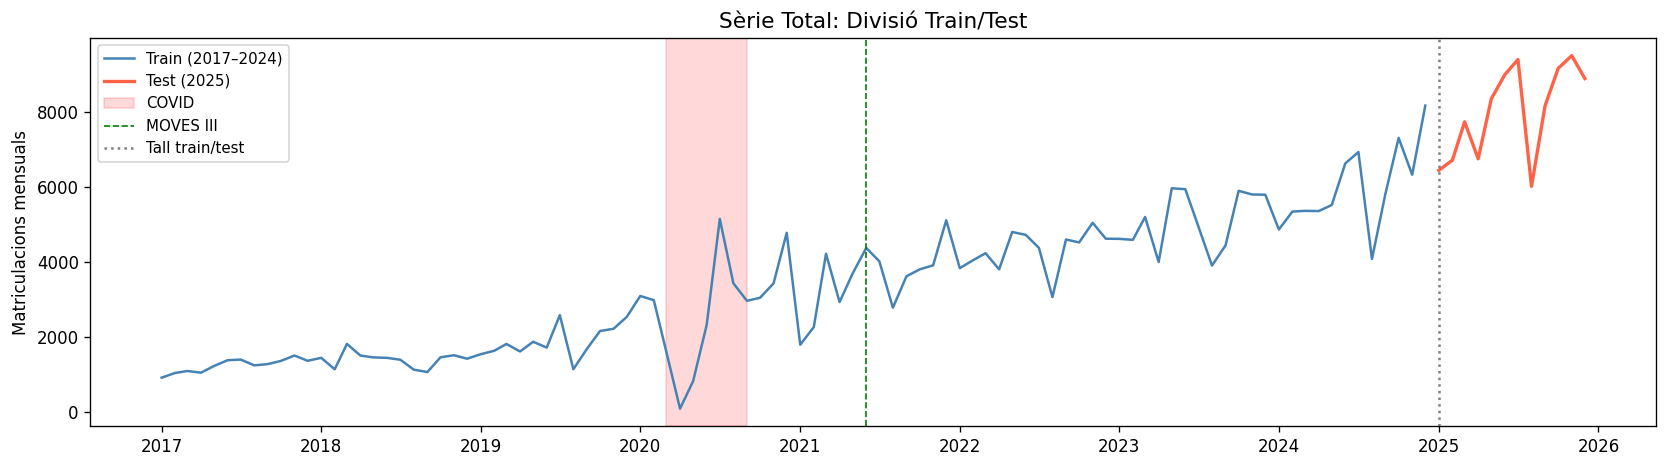

In [7]:
train_tot = df_train[df_train['Tecnologia'] == 'Total'].set_index('date')['Matriculacions']
test_tot  = df_test[df_test['Tecnologia'] == 'Total'].set_index('date')['Matriculacions']

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train_tot.index, train_tot.values, color='steelblue', lw=1.5, label='Train (2017–2024)')
ax.plot(test_tot.index,  test_tot.values,  color='tomato',    lw=2,   label='Test (2025)')
ax.axvspan(pd.Timestamp(COVID_START), pd.Timestamp(COVID_END),
           alpha=0.15, color='red', label='COVID')
ax.axvline(pd.Timestamp(MOVES3_START), color='green', ls='--', lw=1, label='MOVES III')
ax.axvline(pd.Timestamp(TEST_START), color='gray', ls=':', lw=1.5, label='Tall train/test')
ax.set_title('Sèrie Total: Divisió Train/Test', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_08_train_test_split.png', bbox_inches='tight')
plt.show()

### Decisions metodològiques sobre els períodes especials

Els mesos del COVID (març–setembre 2020, 7 mesos) no s'han eliminat del conjunt d'entrenament. Excloure'ls crearia un buit en la sèrie temporal que complicaria l'estimació dels paràmetres ARIMA, i tampoc resoldria el problema de fons: el model seguiria veient el salt de recuperació posterior com una anomalia. En lloc d'eliminar, s'opta per marcar els 7 mesos afectats amb una variable dummy binària (`covid_dummy = 1`). Aquesta variable pot ser usada com a regressora exògena en models que ho permetin (SARIMAX), de manera que l'impacte del COVID quedi aïllat del component estacional i de tendència. Per als models sense variables exògenes, com AutoSARIMA o TBATS, la caiguda de 2020 s'inclou en l'ajust igual que qualsevol altra observació.

De forma similar, el llançament del programa MOVES III (juny 2021) queda marcat amb `moves3_dummy = 1` a partir d'aquella data. Durant el període de test (2025), el COVID és zero per definició i MOVES III és actiu tots els mesos, de manera que en la pràctica les dues dummies no aporten variació addicional al test i les prediccions d'AutoSARIMA i SARIMAX resulten idèntiques.

## 5. Guardar outputs


In [8]:
df_train.to_csv(DATA_DIR / 'train_set.csv', index=False)
df_test.to_csv(DATA_DIR / 'test_set.csv',   index=False)

all_techs = TECNOLOGIES_MODELITZABLES + ['Total']
pivot_train = get_pivot(df_train, tecnologies=all_techs)
pivot_test  = get_pivot(df_test,  tecnologies=all_techs)
pivot_train.to_csv(DATA_DIR / 'pivot_train.csv')
pivot_test.to_csv(DATA_DIR / 'pivot_test.csv')

print('Fitxers guardats a data/processed/:')
print(f'  train_set.csv   → {len(df_train)} files ({n_train} mesos × 9 tecn.)')
print(f'  test_set.csv    → {len(df_test)} files ({n_test} mesos × 9 tecn.)')
print(f'  pivot_train.csv → {pivot_train.shape} (mesos × tecnologies)')
print(f'  pivot_test.csv  → {pivot_test.shape} (mesos × tecnologies)')

Fitxers guardats a data/processed/:
  train_set.csv   → 864 files (96 mesos × 9 tecn.)
  test_set.csv    → 108 files (12 mesos × 9 tecn.)
  pivot_train.csv → (96, 7) (mesos × tecnologies)
  pivot_test.csv  → (12, 7) (mesos × tecnologies)
